In [1]:
import pandas as pd
from sqlalchemy import create_engine
import pymysql
from sklearn.preprocessing import MinMaxScaler
import numpy as np
from dotenv import load_dotenv
import os

load_dotenv() # betölti a .env fájlt

db_host = os.getenv("DB_HOST")
db_user = os.getenv("DB_USER")
db_password = os.getenv("DB_PASSWORD")
db_name = os.getenv("DB_NAME")

engine = create_engine( f"mysql+pymysql://{db_user}:{db_password}@{db_host}/{db_name}")

query = """
SELECT 
    valid_time,
    temp_c,
    rh,
    wind_speed,
    wind_dir,
    sp,
    tp
FROM era5_adatok_fix
ORDER BY valid_time
"""

df = pd.read_sql(query, engine, parse_dates=["valid_time"])
df = df.sort_values("valid_time").reset_index(drop=True)
df["valid_time_num"] = df["valid_time"].astype("int64") // 10**9


features = [
    "valid_time_num",
    "temp_c",
    "rh",
    "wind_speed",
    "wind_dir",
    "sp",
    "tp"
]

target = "temp_c"

# input_window = 48
# output_horizon = 6
input_window = 336
output_horizon = 48

scaler = MinMaxScaler()
df[features + [target]] = scaler.fit_transform(df[features + [target]])

df = df.replace([np.inf, -np.inf], np.nan)
df = df.ffill().bfill()

def create_windowed_dataset(df, features, target, input_window, output_horizon):
    X, y = [], []
    data = df[features + [target]].values
    for i in range(len(data) - input_window - output_horizon):
        X.append(data[i:i+input_window, :len(features)])
        y.append(data[i+input_window:i+input_window+output_horizon, -1])
    return np.array(X), np.array(y)

X, y = create_windowed_dataset(df, features, target, input_window, output_horizon)

# split = int(len(X) * 0.8)
split = int(len(X) * 0.9997752)
X_train, X_test = X[:split], X[split:]
y_train, y_test = y[:split], y[split:]

In [2]:
#TCN
import tensorflow as tf
from tensorflow.keras import layers, models

gpus = tf.config.experimental.list_physical_devices('GPU')
if gpus:
    try:
        for gpu in gpus:
            tf.config.experimental.set_memory_growth(gpu, True)
        print("GPU memory growth enabled")
    except RuntimeError as e:
        print(e)


input_shape = (input_window, len(features))

inputs = layers.Input(shape=input_shape)
x = layers.Permute((2, 1))(inputs)  # (batch, features, time)
x = layers.Conv1D(64, kernel_size=3, padding="causal", activation="relu")(x)
x = layers.Conv1D(64, kernel_size=3, padding="causal", activation="relu")(x)
x = layers.GlobalAveragePooling1D()(x)
outputs = layers.Dense(output_horizon)(x)

tcn_model = models.Model(inputs, outputs)
tcn_model.compile(optimizer="adam", loss="mse", metrics=["mae"])

history = tcn_model.fit(
    X_train, y_train,
    validation_split=0.1,
    epochs=15,
    batch_size=64
)


2026-02-15 10:56:58.849224: I tensorflow/core/platform/cpu_feature_guard.cc:210] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


GPU memory growth enabled


I0000 00:00:1771153035.858208    1377 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13756 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:10.0, compute capability: 7.5
2026-02-15 10:57:31.738835: W external/local_xla/xla/tsl/framework/cpu_allocator_impl.cc:84] Allocation of 6386347968 exceeds 10% of free system memory.
2026-02-15 10:57:44.927350: W external/local_xla/xla/tsl/framework/cpu_allocator_impl.cc:84] Allocation of 6386347968 exceeds 10% of free system memory.


Epoch 1/15


2026-02-15 10:57:54.814399: I external/local_xla/xla/service/service.cc:163] XLA service 0x7435f4007570 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
2026-02-15 10:57:54.814433: I external/local_xla/xla/service/service.cc:171]   StreamExecutor device (0): Tesla T4, Compute Capability 7.5
2026-02-15 10:57:55.142703: I tensorflow/compiler/mlir/tensorflow/utils/dump_mlir_util.cc:269] disabling MLIR crash reproducer, set env var `MLIR_CRASH_REPRODUCER_DIRECTORY` to enable.
2026-02-15 10:57:55.903422: I external/local_xla/xla/stream_executor/cuda/cuda_dnn.cc:473] Loaded cuDNN version 91900


   52/10607 ━━━━━━━━━━━━━━━━━━━━ 31s 3ms/step - loss: 0.1915 - mae: 0.3447

I0000 00:00:1771153080.241085    1531 device_compiler.h:196] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


10607/10607 ━━━━━━━━━━━━━━━━━━━━ 44s 3ms/step - loss: 0.0026 - mae: 0.0348 - val_loss: 0.0015 - val_mae: 0.0293
Epoch 2/15
10607/10607 ━━━━━━━━━━━━━━━━━━━━ 32s 3ms/step - loss: 0.0014 - mae: 0.0276 - val_loss: 0.0017 - val_mae: 0.0313
Epoch 3/15
10607/10607 ━━━━━━━━━━━━━━━━━━━━ 31s 3ms/step - loss: 0.0012 - mae: 0.0263 - val_loss: 0.0013 - val_mae: 0.0261
Epoch 4/15
10607/10607 ━━━━━━━━━━━━━━━━━━━━ 29s 3ms/step - loss: 0.0012 - mae: 0.0257 - val_loss: 0.0012 - val_mae: 0.0256
Epoch 5/15
10607/10607 ━━━━━━━━━━━━━━━━━━━━ 28s 3ms/step - loss: 0.0012 - mae: 0.0253 - val_loss: 0.0011 - val_mae: 0.0250
Epoch 6/15
10607/10607 ━━━━━━━━━━━━━━━━━━━━ 30s 3ms/step - loss: 0.0011 - mae: 0.0250 - val_loss: 0.0011 - val_mae: 0.0243
Epoch 7/15
10607/10607 ━━━━━━━━━━━━━━━━━━━━ 30s 3ms/step - loss: 0.0011 - mae: 0.0248 - val_loss: 0.0012 - val_mae: 0.0257
Epoch 8/15
10607/10607 ━━━━━━━━━━━━━━━━━━━━ 30s 3ms/step - loss: 0.0011 - mae: 0.0246 - val_loss: 0.0011 - val_mae: 0.0244
Epoch 9/15
10607/10607 ━━━━

In [3]:
y_pred = tcn_model.predict(X_test)

y_pred_flat = y_pred.reshape(-1, 1)
y_test_flat = y_test.reshape(-1, 1)

y_pred_tcn_real = scaler.inverse_transform(
    np.hstack([np.zeros((len(y_pred_flat), len(features))), y_pred_flat])
)[:, -1]

y_test_real = scaler.inverse_transform(
    np.hstack([np.zeros((len(y_test_flat), len(features))), y_test_flat])
)[:, -1]


6/6 ━━━━━━━━━━━━━━━━━━━━ 1s 97ms/step


In [4]:
from sklearn.metrics import mean_squared_error, mean_absolute_error

mse = mean_squared_error(y_test_real, y_pred_tcn_real)
mae = mean_absolute_error(y_test_real, y_pred_tcn_real)
rmse = np.sqrt(mse)

print("TCN – MSE:", mse)
print("TCN – MAE:", mae)
print("TCN – RMSE:", rmse)


TCN – MSE: 2.544064949194898
TCN – MAE: 1.2230503230782819
TCN – RMSE: 1.5950125232094254


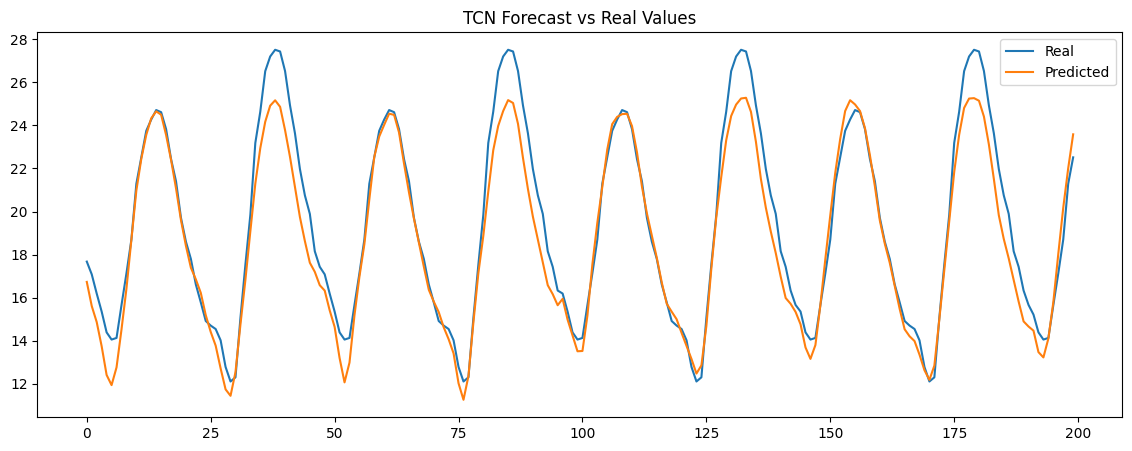

In [5]:
import matplotlib.pyplot as plt

plt.figure(figsize=(14,5))
plt.plot(y_test_real[:200], label="Real")
plt.plot(y_pred_tcn_real[:200], label="Predicted")
plt.legend()
plt.title("TCN Forecast vs Real Values")
plt.show()


In [6]:
#TimesNET
inputs = layers.Input(shape=input_shape)

x1 = layers.Conv1D(64, kernel_size=3, padding="causal", activation="relu")(inputs)
x2 = layers.Conv1D(64, kernel_size=5, padding="causal", activation="relu")(inputs)
x3 = layers.Conv1D(64, kernel_size=7, padding="causal", activation="relu")(inputs)

x = layers.Concatenate()([x1, x2, x3])
x = layers.GlobalAveragePooling1D()(x)
x = layers.Dense(64, activation="relu")(x)
outputs = layers.Dense(output_horizon)(x)

timesnet_like_model = models.Model(inputs, outputs)
timesnet_like_model.compile(optimizer="adam", loss="mse", metrics=["mae"])

history_times = timesnet_like_model.fit(
    X_train, y_train,
    validation_split=0.1,
    epochs=15,
    batch_size=64
)


2026-02-15 11:05:52.733734: W external/local_xla/xla/tsl/framework/cpu_allocator_impl.cc:84] Allocation of 6386347968 exceeds 10% of free system memory.
2026-02-15 11:06:03.243105: W external/local_xla/xla/tsl/framework/cpu_allocator_impl.cc:84] Allocation of 6386347968 exceeds 10% of free system memory.


Epoch 1/15
10607/10607 ━━━━━━━━━━━━━━━━━━━━ 86s 8ms/step - loss: 0.0079 - mae: 0.0686 - val_loss: 0.0040 - val_mae: 0.0487
Epoch 2/15
10607/10607 ━━━━━━━━━━━━━━━━━━━━ 73s 7ms/step - loss: 0.0037 - mae: 0.0467 - val_loss: 0.0040 - val_mae: 0.0491
Epoch 3/15
10607/10607 ━━━━━━━━━━━━━━━━━━━━ 73s 7ms/step - loss: 0.0034 - mae: 0.0446 - val_loss: 0.0035 - val_mae: 0.0452
Epoch 4/15
10607/10607 ━━━━━━━━━━━━━━━━━━━━ 73s 7ms/step - loss: 0.0032 - mae: 0.0432 - val_loss: 0.0033 - val_mae: 0.0440
Epoch 5/15
10607/10607 ━━━━━━━━━━━━━━━━━━━━ 74s 7ms/step - loss: 0.0031 - mae: 0.0423 - val_loss: 0.0037 - val_mae: 0.0466
Epoch 6/15
10607/10607 ━━━━━━━━━━━━━━━━━━━━ 76s 7ms/step - loss: 0.0030 - mae: 0.0416 - val_loss: 0.0033 - val_mae: 0.0436
Epoch 7/15
10607/10607 ━━━━━━━━━━━━━━━━━━━━ 73s 7ms/step - loss: 0.0029 - mae: 0.0410 - val_loss: 0.0033 - val_mae: 0.0441
Epoch 8/15
10607/10607 ━━━━━━━━━━━━━━━━━━━━ 75s 7ms/step - loss: 0.0028 - mae: 0.0406 - val_loss: 0.0034 - val_mae: 0.0451
Epoch 9/15
10607

In [7]:
y_pred_times = timesnet_like_model.predict(X_test)

# Flatten (multi-step → 1D)
y_pred_flat = y_pred_times.reshape(-1, 1)
y_test_flat = y_test.reshape(-1, 1)

# Visszaskálázás (csak a target oszlopot)
y_pred_times_real = scaler.inverse_transform(
    np.hstack([np.zeros((len(y_pred_flat), len(features))), y_pred_flat])
)[:, -1]

y_test_real = scaler.inverse_transform(
    np.hstack([np.zeros((len(y_test_flat), len(features))), y_test_flat])
)[:, -1]


6/6 ━━━━━━━━━━━━━━━━━━━━ 1s 133ms/step


In [8]:

mse_times = mean_squared_error(y_test_real, y_pred_times_real)
mae_times = mean_absolute_error(y_test_real, y_pred_times_real)
rmse_times = np.sqrt(mse_times)

print("TimesNet-like – MSE:", mse_times)
print("TimesNet-like – MAE:", mae_times)
print("TimesNet-like – RMSE:", rmse_times)


TimesNet-like – MSE: 4.815826740999024
TimesNet-like – MAE: 1.7789560405197884
TimesNet-like – RMSE: 2.194499200500885


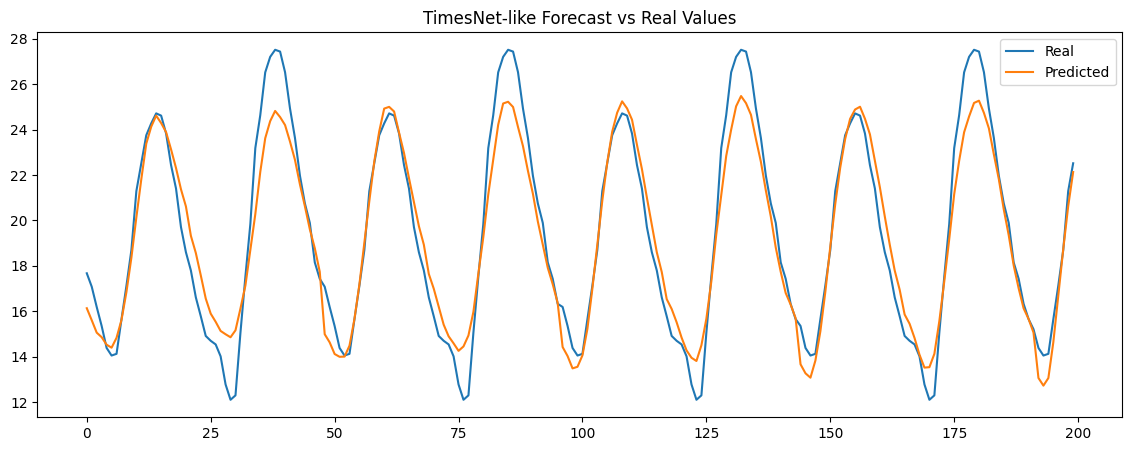

In [9]:

plt.figure(figsize=(14,5))
plt.plot(y_test_real[:200], label="Real")
plt.plot(y_pred_times_real[:200], label="Predicted")
plt.legend()
plt.title("TimesNet-like Forecast vs Real Values")
plt.show()


In [10]:
#Summary
from sklearn.metrics import mean_squared_error, mean_absolute_error

def evaluate_model(model, name):
    y_pred = model.predict(X_test)
    y_pred_flat = y_pred.reshape(-1, 1)
    y_test_flat = y_test.reshape(-1, 1)

    y_pred_real = scaler.inverse_transform(
        np.hstack([np.zeros((len(y_pred_flat), len(features))), y_pred_flat])
    )[:, -1]

    y_test_real = scaler.inverse_transform(
        np.hstack([np.zeros((len(y_test_flat), len(features))), y_test_flat])
    )[:, -1]

    mse = mean_squared_error(y_test_real, y_pred_real)
    mae = mean_absolute_error(y_test_real, y_pred_real)
    rmse = np.sqrt(mse)
    print(f"{name} – MSE: {mse:.4f}, MAE: {mae:.4f}, RMSE: {rmse:.4f}")
    return mse, mae, rmse

evaluate_model(tcn_model, "TCN")
evaluate_model(timesnet_like_model, "TimesNet-like")


6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step 
TCN – MSE: 2.5441, MAE: 1.2231, RMSE: 1.5950
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step 
TimesNet-like – MSE: 4.8158, MAE: 1.7790, RMSE: 2.1945


(4.815826740999024, 1.7789560405197884, np.float64(2.194499200500885))

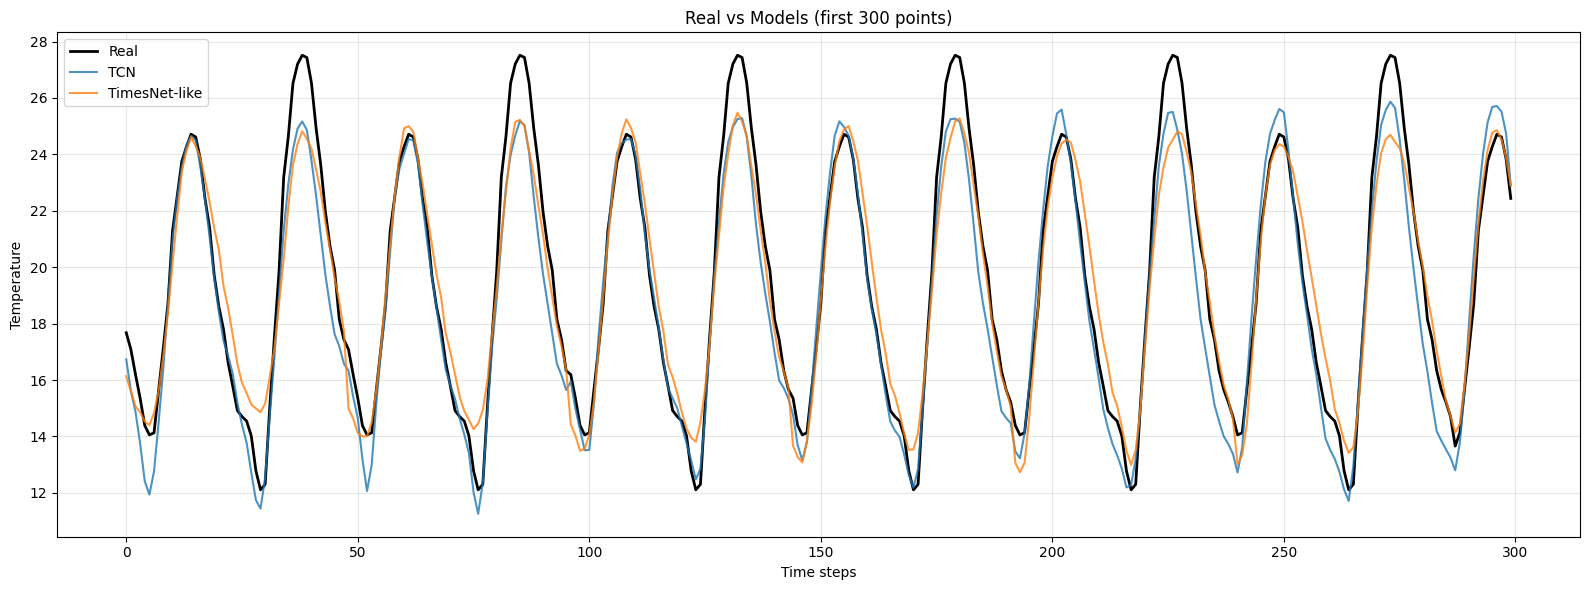

In [11]:

# hány pontot nézzünk meg a grafikonon
N = 300  # nyugodtan állítsd, pl. 200, 500 stb.

plt.figure(figsize=(16, 6))

plt.plot(y_test_real[:N], label="Real", color="black", linewidth=2)

plt.plot(y_pred_tcn_real[:N],   label="TCN",           alpha=0.8)
plt.plot(y_pred_times_real[:N], label="TimesNet-like", alpha=0.8)

plt.title(f"Real vs Models (first {N} points)")
plt.xlabel("Time steps")
plt.ylabel("Temperature")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


In [12]:
#Modellek mentése
tcn_model.save("models3/tcn_model.keras")
timesnet_like_model.save("models3/timesnet_model.keras")

#Visszatöltés
#from tensorflow.keras.models import load_model

#tcn_model = load_model("models/tcn_model")
#timesnet_model = load_model("models/timesnet_model")

#Scaler mentése!
import joblib
joblib.dump(scaler, "models3/scaler.pkl")

#Visszatöltés:
#scaler = joblib.load("models/scaler.pkl")

#Features mentése
import json
json.dump(features, open("models3/features.json", "w"))

#Visszatöltés
#features = json.load(open("models/features.json"))

#Windows paraméterek:
json.dump(
    {"input_window": input_window, "output_horizon": output_horizon},
    open("models3/window_params.json", "w")
)

#Visszatöltés
#params = json.load(open("models/window_params.json"))
#input_window = params["input_window"]
#output_horizon = params["output_horizon"]

